# Proyecto: Análisis y Predicción de Costos Médicos (Insurance)
**Metodología CRISP-DM**

Este notebook contiene los 8 pasos requeridos para la creación del modelo, evaluación, predicciones y automatización.

> Automatically generated by Colab.  
> Original file located at: https://colab.research.google.com/drive/1wI8zJHZLDIxdBJe2ZGfRbPkEHHgf63Ol



## Propuesta al problema 1: Que la aseguradora entienda los datos de sus afiliados

### 1. Cargar el dataset del proyecto

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cargar el dataset desde una URL pública (para que funcione directo en Colab)
url = "https://raw.githubusercontent.com/stedy/machine-learning-with-r-datasets/master/insurance.csv"
df = pd.read_csv(url)
print("Dataset cargado correctamente. Filas:", df.shape[0])
display(df.head())

Dataset cargado correctamente. Filas: 1338


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 2. Analizar las clases y generar gráficos representativos

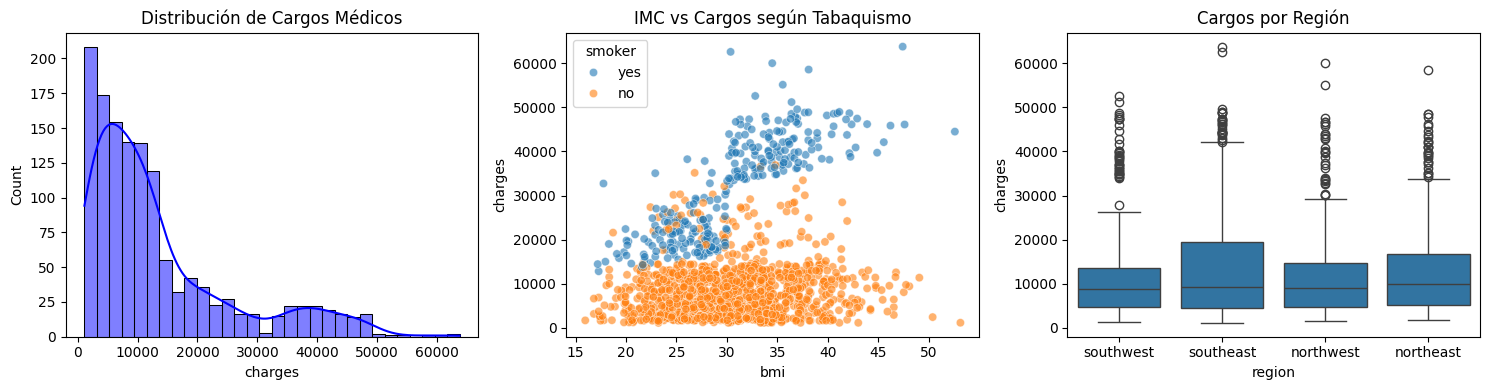

In [ ]:
plt.figure(figsize=(15, 4))

# Gráfico 1: Distribución de Cargos (Variable objetivo)
plt.subplot(1, 3, 1)
sns.histplot(df['charges'], kde=True, color='blue')
plt.title('Distribución de Cargos Médicos')

# Gráfico 2: Relación IMC vs Cargos (segmentado por fumador)
plt.subplot(1, 3, 2)
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, alpha=0.6)
plt.title('IMC vs Cargos según Tabaquismo')

# Gráfico 3: Boxplot de Cargos por Región
plt.subplot(1, 3, 3)
sns.boxplot(x='region', y='charges', data=df)
plt.title('Cargos por Región')

plt.tight_layout()
plt.show()

### 📊 Interpretación de los gráficos del EDA

**Gráfico 1: Distribución de Cargos Médicos (`sns.histplot`)**

Este histograma muestra cómo se distribuyen los costos médicos (`charges`) entre todos los pacientes. Se observa una **distribución con asimetría positiva (sesgada a la derecha)**: la mayoría de los pacientes generan costos relativamente bajos, pero existe un grupo reducido con costos muy elevados que estiran la "cola" del gráfico hacia la derecha. Esta característica es fundamental para entender el resto del análisis, ya que implica que la mayoría de los modelos lineales pueden subestimar los costos más altos.

**Gráfico 2: Relación IMC vs Cargos según Tabaquismo (`sns.scatterplot`)**

Este diagrama de dispersión es clave para identificar los principales determinantes del costo. En el eje X se muestra el Índice de Masa Corporal (IMC) y en el Y los cargos médicos, con los puntos coloreados según si el paciente es fumador o no:

- **No fumadores**: se agrupan en la zona baja del gráfico (cargos bajos) y su relación con el IMC es más débil.
- **Fumadores**: se distribuyen en una nube mucho más alta y dispersa. La combinación de **tabaquismo + IMC elevado** genera los costos más altos del dataset, lo que convierte al tabaquismo en el factor de riesgo de mayor impacto.

**Gráfico 3: Cargos por Región (`sns.boxplot`)**

Este diagrama de caja compara la distribución de los cargos médicos entre las cuatro regiones. La **caja** representa el rango intercuartílico (donde se concentra el 50% central de los datos), la **línea central** es la mediana y los **bigotes** muestran el resto de la distribución. Los puntos fuera de los bigotes son valores atípicos. Se observa que la región **southeast** tiene una mediana ligeramente más alta y mayor dispersión, lo que sugiere que podría ser una región con mayor riesgo de costos elevados y justifica la inclusión de la variable `region` en el modelo.

### 3. Preparar los datos y seleccionar las variables dependientes e independientes

In [ ]:
# Encoding categórico
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df = pd.get_dummies(df, columns=['region'], drop_first=True)

# Feature Engineering (Igual que en Power BI)
df['is_obese'] = (df['bmi'] >= 30).astype(int)
df['smoker_bmi'] = df['smoker'] * df['bmi']
df['smoker_age'] = df['smoker'] * df['age']
df['smoker_obese'] = df['smoker'] * df['is_obese']

# Variables independientes (X) y dependiente (y)
X = df[['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest',
        'region_southeast', 'region_southwest', 'is_obese',
        'smoker_bmi', 'smoker_age', 'smoker_obese']]
y = df['charges']

print("Variables independientes listas. Total features:", X.shape[1])

print("=== DATASET PREPARADO ===")
display(X)

Variables independientes listas. Total features: 12
=== DATASET PREPARADO ===


,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,is_obese,smoker_bmi,smoker_age,smoker_obese
0,19,0,27.900,0,1,False,False,True,0,27.90,19,0
1,18,1,33.770,1,0,False,True,False,1,0.00,0,0
2,28,1,33.000,3,0,False,True,False,1,0.00,0,0
3,33,1,22.705,0,0,True,False,False,0,0.00,0,0
4,32,1,28.880,0,0,True,False,False,0,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,True,False,False,1,0.00,0,0
1334,18,0,31.920,0,0,False,False,False,1,0.00,0,0
1335,18,0,36.850,0,0,False,True,False,1,0.00,0,0
1336,21,0,25.800,0,0,False,False,True,0,0.00,0,0


### 4. Separar los datos en conjuntos de entrenamiento y test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Datos de entrenamiento: {X_train.shape[0]} filas")
print(f"Datos de prueba: {X_test.shape[0]} filas")

Datos de entrenamiento: 1070 filas
Datos de prueba: 268 filas


## Propuesta al problema 2: Generar un modelo predictivo con explicabilidad para la prediccion de primas

### 5. Entrenar el modelo y analizar si los pasos previos fueron suficientes
### 6. Evaluar los resultados del modelo utilizando métricas de desempeño

In [ ]:
# 5. Entrenar el modelo
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Evaluar resultados
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("=== MÉTRICAS DE EVALUACIÓN ===")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MAE (Error Absoluto Medio): ${mae:,.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:,.2f}")

print("\nConclusión del análisis: El R² es alto (mayor a 0.8).")
print("Esto significa que las etapas previas (Feature Engineering) fueron suficientes")
print("para que el modelo lineal explique la gran mayoría de la varianza en los cargos.")

=== MÉTRICAS DE EVALUACIÓN ===
R² (Coeficiente de Determinación): 0.8792
MAE (Error Absoluto Medio): $2,377.86
RMSE (Raíz del Error Cuadrático Medio): $4,330.34

Conclusión del análisis: El R² es alto (mayor a 0.8).
Esto significa que las etapas previas (Feature Engineering) fueron suficientes
para que el modelo lineal explique la gran mayoría de la varianza en los cargos.


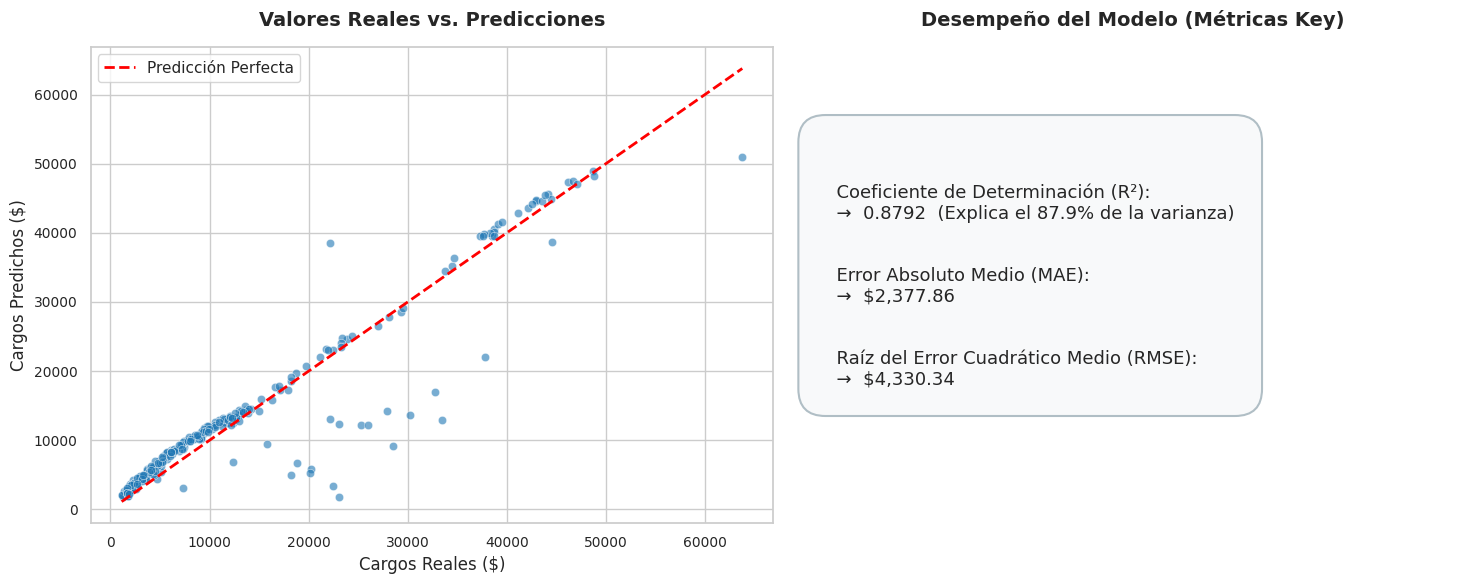

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Asegurar que las variables necesarias existan obteniéndolas del modelo y el set de prueba
y_pred = model.predict(X_test)

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Gráfico de Dispersión: Reales vs Predichos
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='#1f77b4', ax=axes[0])
# Línea de referencia (predicción perfecta)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', lw=2, label='Predicción Perfecta')

axes[0].set_title('Valores Reales vs. Predicciones', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Cargos Reales ($)', fontsize=12)
axes[0].set_ylabel('Cargos Predichos ($)', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].tick_params(labelsize=10)

# 2. Panel Visual de Métricas
axes[1].axis('off')  # Ocultar ejes
axes[1].set_title('Desempeño del Modelo (Métricas Key)', fontsize=14, fontweight='bold', pad=15)

# Diseñar tarjetas de texto con las métricas usando las variables del notebook
metricas_texto = (
    f"\n\n"
    f"  Coeficiente de Determinación (R²):\n"
    f"  →  {r2:.4f}  (Explica el {r2*100:.1f}% de la varianza)\n\n\n"
    f"  Error Absoluto Medio (MAE):\n"
    f"  →  ${mae:,.2f}\n\n\n"
    f"  Raíz del Error Cuadrático Medio (RMSE):\n"
    f"  →  ${rmse:,.2f}"
)

# Agregar caja de texto con formato de tarjeta
bbox_props = dict(boxstyle="round,pad=1.5", fc="#f8f9fa", ec="#b0bec5", lw=1.5)
axes[1].text(0.05, 0.8, metricas_texto, transform=axes[1].transAxes,
             fontsize=13, verticalalignment='top', bbox=bbox_props, fontfamily='sans-serif')

plt.tight_layout()
plt.show()

###  Interpretación del gráfico "Reales vs. Predicciones"

El gráfico compara los **valores reales** (eje X) con las **predicciones del modelo** (eje Y). La línea roja punteada representa la "predicción perfecta" (donde real = predicho). Aunque la mayoría de los puntos se concentran alrededor de la diagonal (buen ajuste general), se observa claramente un **patrón en forma de embudo**: los puntos por **debajo** de la línea diagonal aumentan a medida que los cargos reales son más altos.

**¿Por qué hay tantos puntos por debajo de la diagonal?**

Esto se debe principalmente a la **asimetría positiva de los datos** (vista en el histograma inicial). La regresión lineal se ajusta a la "mayoría" de los casos, pero los valores extremos (la cola derecha con costos muy altos) son poco frecuentes, por lo que el modelo tiende a **subestimarlos**. El resultado es que, para los pacientes con cargos muy elevados, la predicción queda por debajo del valor real.

**Heterocedasticidad:** la dispersión de los errores no es constante, sino que crece a medida que aumentan los valores reales. Esto es una violación del supuesto de homocedasticidad de la regresión lineal y explica el patrón visual en "embudo".

### 7. Utilizar el modelo con nuevos datos para generar 5 predicciones

In [ ]:
# Creamos un DataFrame con 5 pacientes ficticios (mismos formatos que X)
nuevos_pacientes = pd.DataFrame({
    'age': [25, 45, 35, 60, 19],
    'sex': [1, 0, 1, 0, 1],            # 1: Hombre, 0: Mujer
    'bmi': [22.5, 35.1, 28.0, 31.5, 18.9],
    'children': [0, 2, 1, 0, 0],
    'smoker': [0, 1, 0, 1, 0],         # 1: Fuma, 0: No fuma
    'region_northwest': [0, 1, 0, 0, 0],
    'region_southeast': [1, 0, 1, 0, 0],
    'region_southwest': [0, 0, 0, 1, 1],
    'is_obese': [0, 1, 0, 1, 0],
    'smoker_bmi': [0, 35.1, 0, 31.5, 0],
    'smoker_age': [0, 45, 0, 60, 0],
    'smoker_obese': [0, 1, 0, 1, 0]
})

predicciones = model.predict(nuevos_pacientes)
print("=== PREDICCIÓN DE CARGOS PARA 5 NUEVOS PACIENTES ===")
for i, pred in enumerate(predicciones):
    print(f"Paciente {i+1}: ${pred:,.2f}")

=== PREDICCIÓN DE CARGOS PARA 5 NUEVOS PACIENTES ===
Paciente 1: $3,642.86
Paciente 2: $44,183.27
Paciente 3: $6,728.92
Paciente 4: $44,531.45
Paciente 5: $1,458.51


### 8. Proponer e implementar una automatización

In [ ]:
# Creamos una función que recibe datos en crudo, aplica el Feature Engineering y predice.
def predecir_cargo_automatico(age, sexo, bmi, children, fuma, region):
    # 1. Transformaciones básicas
    sexo_num = 1 if sexo.lower() == 'male' else 0
    fuma_num = 1 if fuma.lower() == 'yes' else 0
    is_obese = 1 if bmi >= 30 else 0

    # 2. Crear el registro con el mismo formato que X_train
    datos = {
        'age': [age], 'sex': [sexo_num], 'bmi': [bmi], 'children': [children], 'smoker': [fuma_num],
        'region_northwest': [1 if region.lower() == 'northwest' else 0],
        'region_southeast': [1 if region.lower() == 'southeast' else 0],
        'region_southwest': [1 if region.lower() == 'southwest' else 0],
        'is_obese': [is_obese],
        'smoker_bmi': [fuma_num * bmi],
        'smoker_age': [fuma_num * age],
        'smoker_obese': [fuma_num * is_obese]
    }

    # 3. Predecir
    df_nuevo = pd.DataFrame(datos)
    prediccion = model.predict(df_nuevo)[0]
    return prediccion

# Probando la automatización:
costo_estimado = predecir_cargo_automatico(age=30, sexo='female', bmi=28.5, children=1, fuma='no', region='southeast')
print("=== PRUEBA DE AUTOMATIZACIÓN ===")
print(f"Ingresando datos crudos, el sistema calcula automáticamente un cargo de: ${costo_estimado:,.2f}")

=== PRUEBA DE AUTOMATIZACIÓN ===
Ingresando datos crudos, el sistema calcula automáticamente un cargo de: $5,965.31


### Reflexión grupal
**¿Qué componente técnico de tu proyecto crees que tendrá mayor impacto en el éxito del negocio: el modelo, la automatización o la forma de comunicar los resultados? ¿Por qué?**

**Respuesta:**
Considero que el componente de mayor impacto en el éxito del negocio es **la forma de comunicar los resultados** (la historia que contamos con los datos y el dashboard), aunque los tres son parte de un mismo engranaje.

**¿Por qué?**
1. **El modelo** es el motor técnico, pero un modelo con un R² del 85% no sirve de nada si los tomadores de decisiones (gerentes, agentes de seguros o médicos) no entienden qué significa o cómo usarlo. La regresión lineal es un modelo matemático, pero el negocio necesita respuestas tangibles: *"¿Cuánto le costará a la aseguradora un paciente con obesidad y tabaquismo?"*.
2. **La automatización** es crucial para la eficiencia (por ejemplo, calcular primas de seguros en tiempo real al ingresar los datos de un cliente). Sin embargo, una automatización mal comunicada puede generar desconfianza o ser ignorada por los empleados (efecto "caja negra").
3. **La comunicación** es el puente entre la técnica y el negocio. Un dashboard bien diseñado en Power BI (con KPIs claros, gráficos de dispersión fáciles de leer y conclusiones directas) permite que cualquier persona entienda el insight principal de nuestro análisis: **el tabaquismo combinado con el sobrepeso es el principal detonante de los altos costos médicos**.

En conclusión, un modelo excelente y una automatización perfecta fracasan si no se comunican. Si logramos traducir los hallazgos a un lenguaje visual y accionable, el negocio no solo verá el valor de la Inteligencia Artificial, sino que podrá tomar decisiones estratégicas inmediatas (como campañas de prevención de salud o ajustes de pólizas) basadas en nuestro trabajo.

### 9. Explicabilidad del Modelo (SHAP y LIME)
Para garantizar la trazabilidad y comprender cómo el modelo toma decisiones, implementamos dos de los marcos de explicabilidad más potentes y utilizados en la industria:

1. **SHAP (SHapley Additive exPlanations):** Nos permite entender el impacto global de cada variable en el modelo y explicar predicciones individuales de forma matemáticamente consistente.
2. **LIME (Local Interpretable Model-agnostic Explanations):** Genera explicaciones locales aproximando el modelo complejo con un modelo lineal simple alrededor de una predicción específica.

In [ ]:
# Instalar las librerías necesarias
!pip install shap lime --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Reconstruir datos y modelo si el kernel fue reiniciado o para asegurar tipos limpios
try:
    _ = model, X_train, X_test
except NameError:
    pass

print("Preparando datos y convirtiendo variables a formato numérico estricto...")
url = "https://raw.githubusercontent.com/stedy/machine-learning-with-r-datasets/master/insurance.csv"
df_prep = pd.read_csv(url)
df_prep['sex'] = df_prep['sex'].map({'female': 0, 'male': 1})
df_prep['smoker'] = df_prep['smoker'].map({'no': 0, 'yes': 1})
df_prep = pd.get_dummies(df_prep, columns=['region'], drop_first=True)
df_prep['is_obese'] = (df_prep['bmi'] >= 30).astype(int)
df_prep['smoker_bmi'] = df_prep['smoker'] * df_prep['bmi']
df_prep['smoker_age'] = df_prep['smoker'] * df_prep['age']
df_prep['smoker_obese'] = df_prep['smoker'] * df_prep['is_obese']

X_cols = ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'is_obese', 'smoker_bmi', 'smoker_age', 'smoker_obese']
X_data = df_prep[X_cols].astype(float)  # Forzar tipos float para compatibilidad estricta con NumPy/SHAP
y_data = df_prep['charges']

X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

# Inicializar y graficar SHAP utilizando el recomendador de masker independiente
masker = shap.maskers.Independent(data=X_train)
explainer_shap = shap.LinearExplainer(model, masker)
shap_values = explainer_shap(X_test)

Preparando datos y convirtiendo variables a formato numérico estricto...


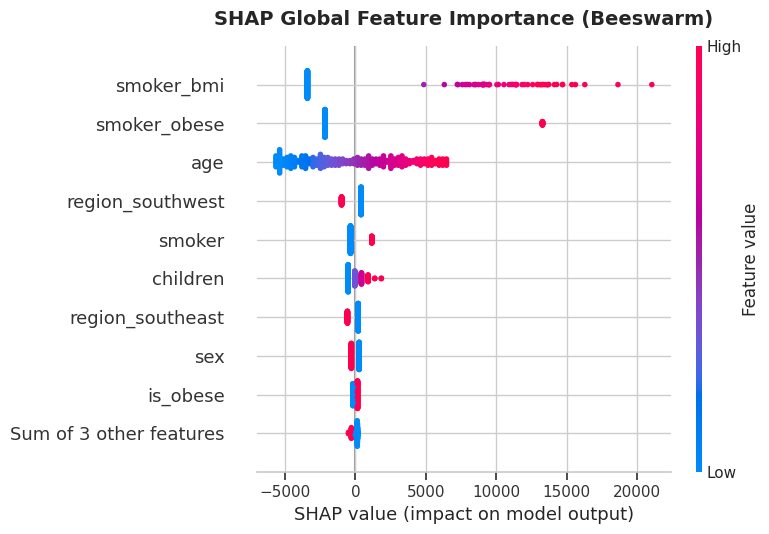

In [ ]:
# Graficar usando la API moderna beeswarm
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, show=False)
plt.title('SHAP Global Feature Importance (Beeswarm)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

=== EXPLICACIÓN SHAP PARA UN PACIENTE ESPECÍFICO ===


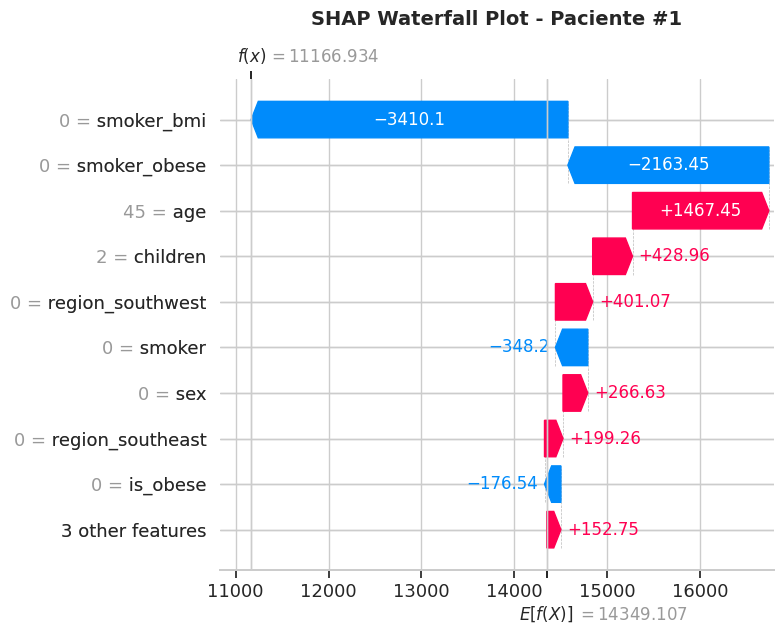

In [ ]:
import matplotlib.pyplot as plt
import shap

# Visualizar una explicación local con SHAP para el primer paciente del set de prueba
print("=== EXPLICACIÓN SHAP PARA UN PACIENTE ESPECÍFICO ===")
# Usamos la representación de cascada (Waterfall Plot) para el primer registro
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[0], show=False)
plt.title('SHAP Waterfall Plot - Paciente #1', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from lime import lime_tabular
from IPython.display import HTML, display
import warnings

# --- SUPRIMIR ADVERTENCIAS MOLESTAS ---
# Ignoramos los FutureWarnings de pandas y los UserWarnings de sklearn
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

# Reconstruir y_pred si no existe (por si acaso)
try:
    _ = y_pred
except NameError:
    y_pred = model.predict(X_test)

# --- 2. EXPLICABILIDAD LOCAL CON LIME ---
# Inicializar el explicador usando .values para evitar el warning de los índices
explainer_lime = lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X_train.columns),
    class_names=['charges'],
    mode='regression'
)

# Elegimos el mismo primer paciente del set de prueba
idx_paciente = 0
instance = X_test.iloc[idx_paciente]

# Creamos una función de predicción "puente" para que reciba un array pero lo convierta a DataFrame
# Esto soluciona el warning: "X does not have valid feature names"
def predict_fn(x):
    return model.predict(pd.DataFrame(x, columns=X_train.columns))

# Generar la explicación
exp = explainer_lime.explain_instance(
    data_row=instance.values,
    predict_fn=predict_fn
)

print(f"=== EXPLICACIÓN LIME (Local) - Paciente #1 ===")
print(f"Valor Real: ${y_test.iloc[idx_paciente]:,.2f}")
print(f"Predicción del Modelo: ${y_pred[idx_paciente]:,.2f}")

# Guardar y renderizar el HTML
html_file = 'lime_explanation.html'
exp.save_to_file(html_file)
print(f"\nExplicación de LIME guardada en '{html_file}'")

with open(html_file, 'r', encoding='utf-8') as f:
    html_content = f.read()

display(HTML(html_content))

=== EXPLICACIÓN LIME (Local) - Paciente #1 ===
Valor Real: $9,095.07
Predicción del Modelo: $11,166.93

Explicación de LIME guardada en 'lime_explanation.html'


### 10. Alternativa y Explicabilidad mediante un Árbol de Decisión
Siguiendo la propuesta académica, entrenamos un modelo de **Árbol de Decisión (Decision Tree Regressor)**. Este modelo no solo captura relaciones no lineales, sino que es auto-explicativo por naturaleza, ya que podemos visualizar las reglas de decisión exactas que sigue para estimar los cargos médicos.

=== COMPARACIÓN DE DESEMPEÑO ===
Regresión Lineal:   R² = 0.8792 | MAE = $2,377.86
Árbol de Decisión:  R² = 0.8542 | MAE = $3,028.77


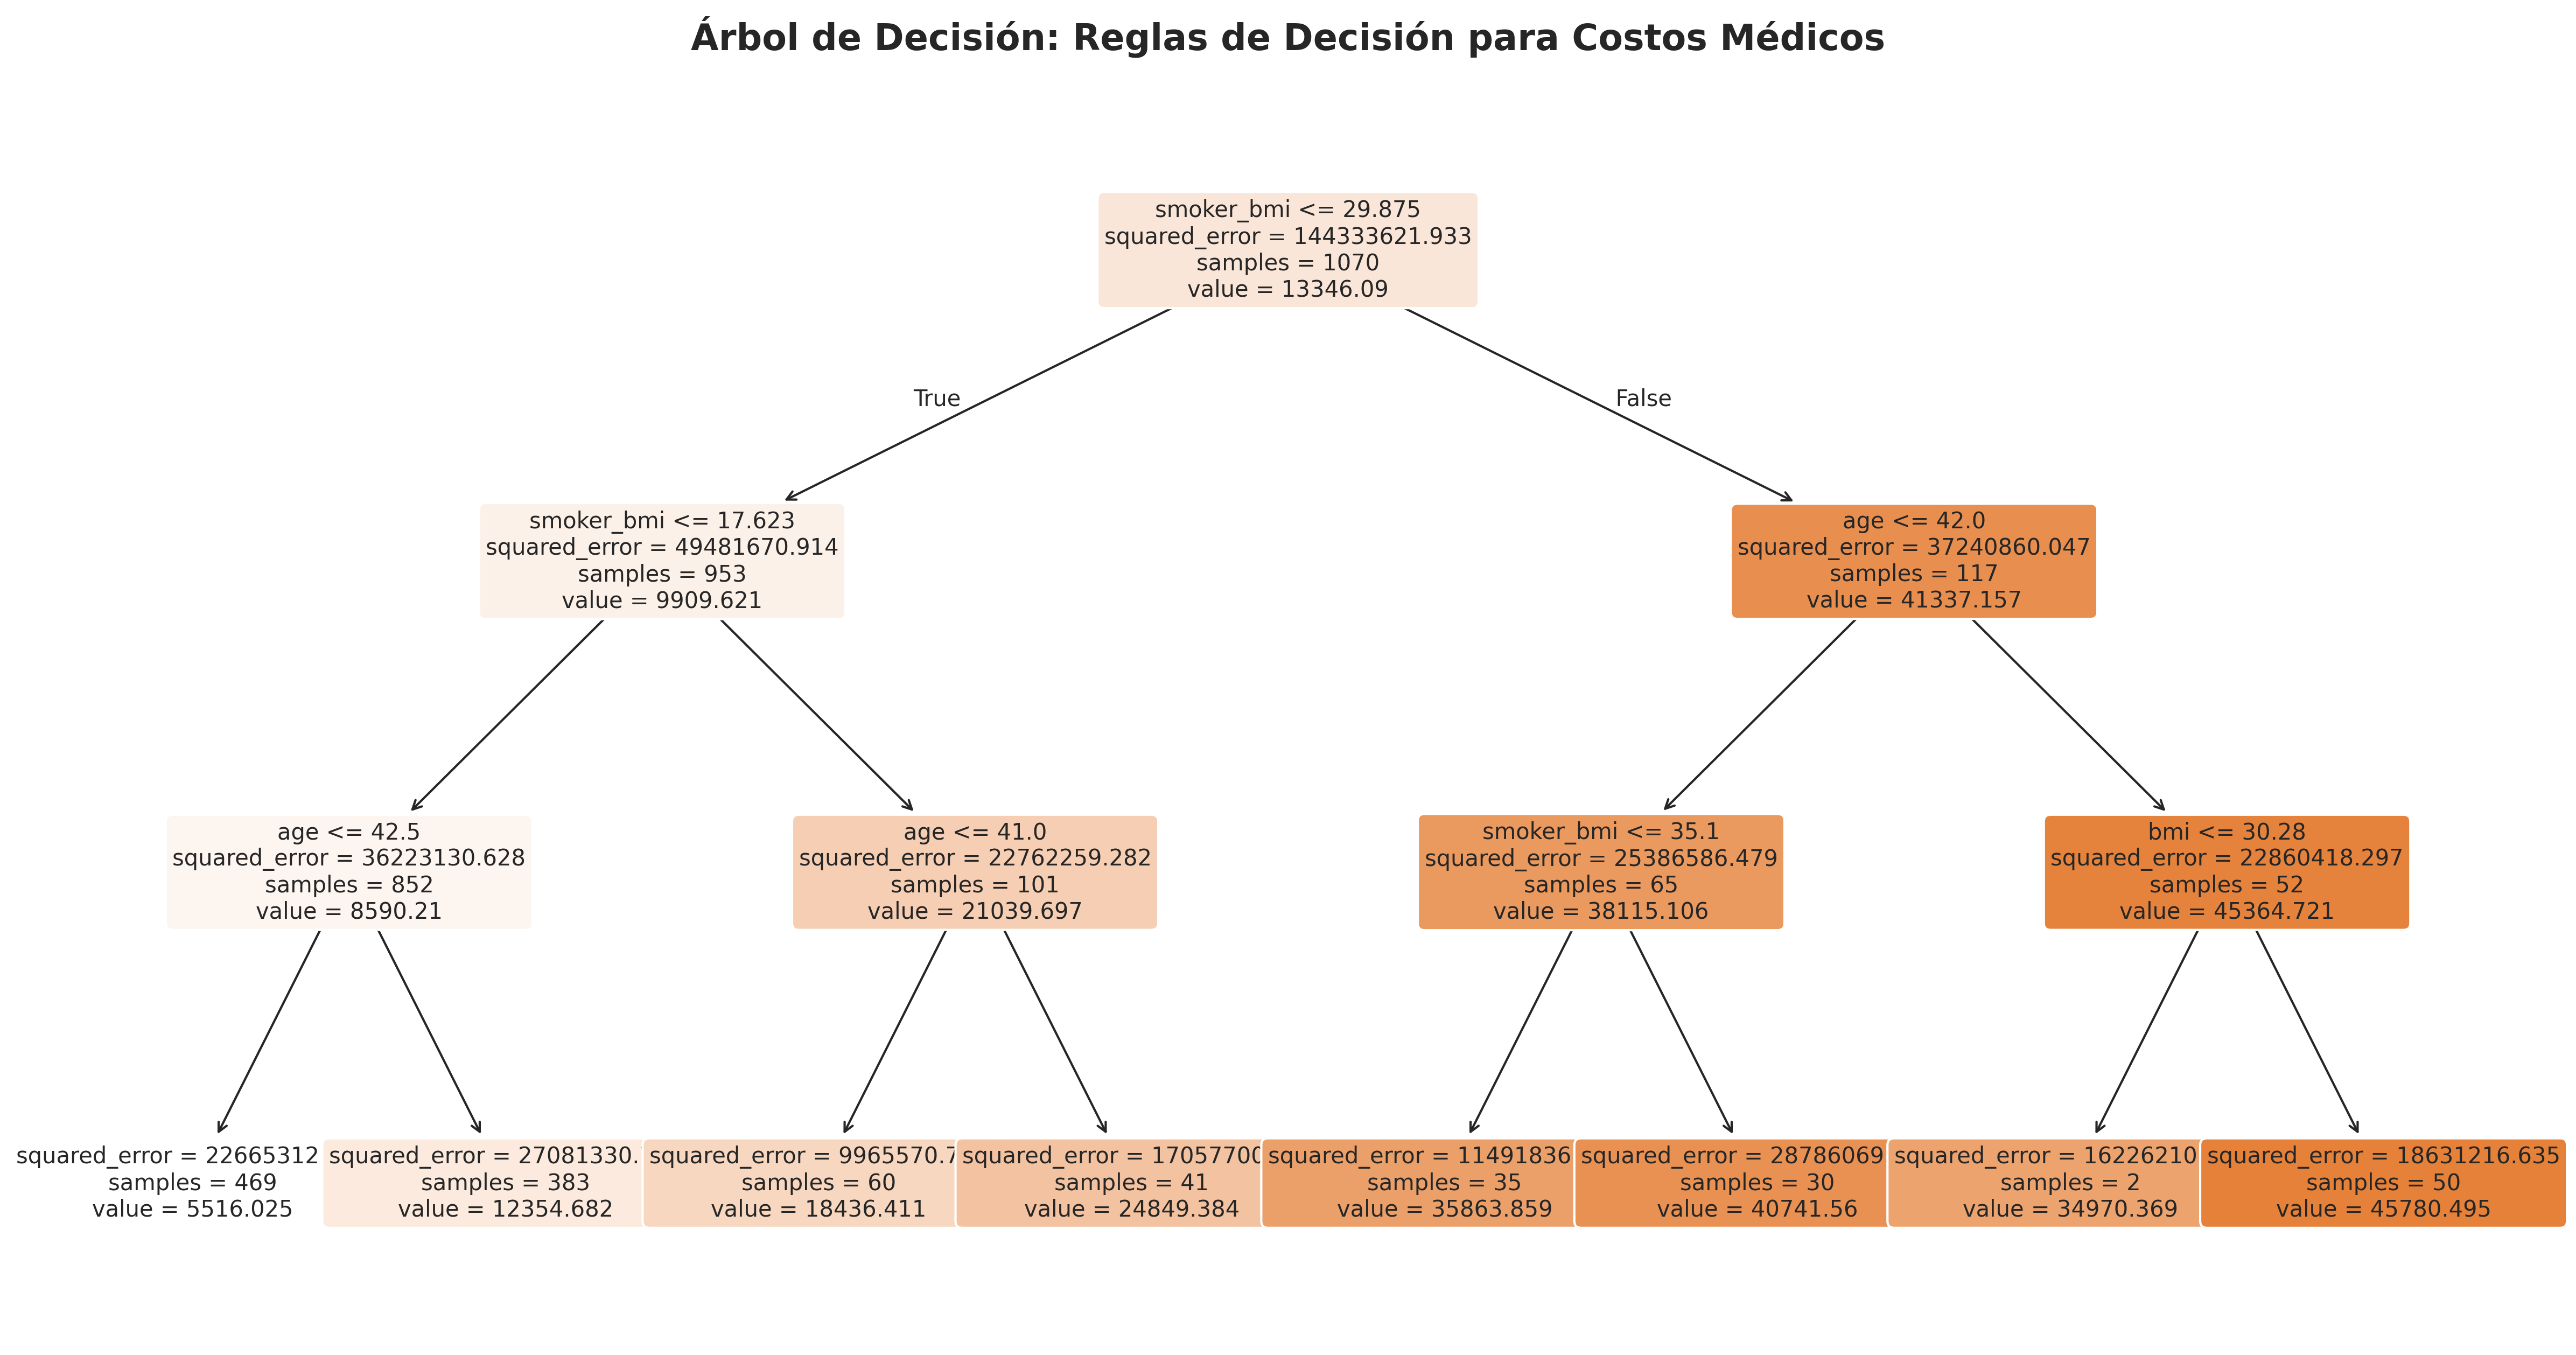

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

# Entrenar un Árbol de Decisión con profundidad limitada para mantener la interpretabilidad (evitar sobreajuste)
modelo_arbol = DecisionTreeRegressor(max_depth=3, random_state=42)
modelo_arbol.fit(X_train, y_train)

# Evaluar el Árbol
y_pred_arbol = modelo_arbol.predict(X_test)
r2_arbol = r2_score(y_test, y_pred_arbol)
mae_arbol = mean_absolute_error(y_test, y_pred_arbol)

print("=== COMPARACIÓN DE DESEMPEÑO ===")
print(f"Regresión Lineal:   R² = {r2:.4f} | MAE = ${mae:,.2f}")
print(f"Árbol de Decisión:  R² = {r2_arbol:.4f} | MAE = ${mae_arbol:,.2f}")

# Visualizar la estructura del árbol de decisión (Reglas lógicas)
plt.figure(figsize=(20, 10), dpi=300)
plot_tree(
    modelo_arbol,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión: Reglas de Decisión para Costos Médicos", fontsize=16, fontweight='bold', pad=20)
plt.show()

#### Interpretación del Árbol de Decisión:
Este gráfico representa el flujo de reglas de decisión que toma el modelo:
- **Nodo Raíz:** El factor que más rápido divide el costo médico (generalmente si es fumador o la combinación de fumador y peso).
- **Hojas (nodos finales):** Contienen el valor promedio de los cargos estimados para los pacientes que caen en esa categoría. Esto permite que el negocio entienda de manera instantánea el "por qué" de cada tarifa sin necesidad de usar fórmulas matemáticas complejas.

## Propuesta problema 3: Generar segmentaciones para crear programas preventivos

### 3.1 Método del Codo (Elbow Method) para Selección de K

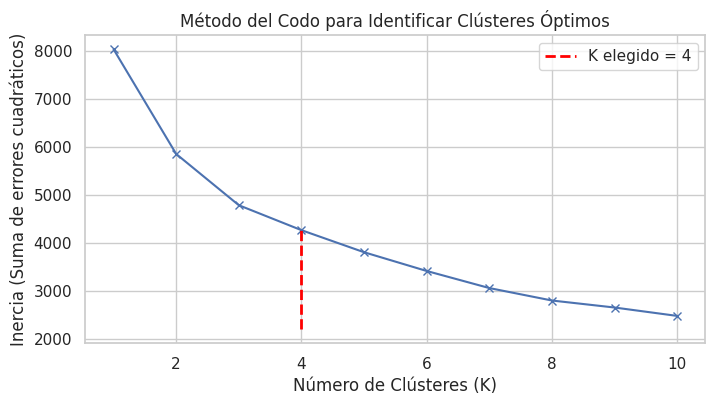

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Selección y preparación de variables para Clustering
# Usamos las variables originales para que la interpretación sea directa, pero las codificamos numéricamente
features_for_clustering = ['age', 'sex', 'bmi', 'children', 'smoker', 'charges']

# Creamos una copia del dataset con las variables transformadas para el modelo
df_clust = df[features_for_clustering].copy()

# Escalamos los datos ya que K-Means es sensible a las diferentes escalas (ej. charges vs children)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clust)

# 2. Método del Codo (Elbow Method)
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

# Graficar el Método del Codo
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, 'bx-')

# Añadimos la línea que va desde el fondo (y=min) hasta el valor de inercia en K=4
inercia_k4 = inertias[3]
plt.vlines(x=4, ymin=plt.ylim()[0], ymax=inercia_k4, colors='red', linestyles='--', linewidth=2, label='K elegido = 4')

plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia (Suma de errores cuadráticos)')
plt.title('Método del Codo para Identificar Clústeres Óptimos')
plt.legend()
plt.grid(True)
plt.show()

#### 📊 Explicación del Método del Codo:
El gráfico del **Método del Codo** muestra cómo disminuye la inercia (la suma de las distancias al cuadrado dentro de cada clúster) a medida que aumentamos el número de grupos ($K$).

* Observamos que el punto de inflexión o 'codo' más claro se encuentra en **$K = 4$**.
* A partir de 4 clústeres, las reducciones en la inercia son menos significativas, lo que nos indica que segmentar en 4 grupos es el balance óptimo entre interpretabilidad y precisión matemática para este conjunto de datos.

=== ANÁLISIS DE SEGMENTOS (K-MEANS con K=4) ===


,Cluster,cantidad_pacientes,cargos_promedio,edad_promedio,imc_promedio,proporcion_fumadores,proporcion_hombres
3,3,273,32097.949677,38.512821,30.753901,1.000000,0.582418
2,2,366,12017.574094,53.117486,31.802240,0.000000,0.480874
0,0,300,9627.846311,40.440000,30.930767,0.003333,0.496667
1,1,399,4276.437888,25.994987,29.355789,0.000000,0.481203


/tmp/ipykernel_1013/1299037686.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='charges', data=df, palette='Set2')


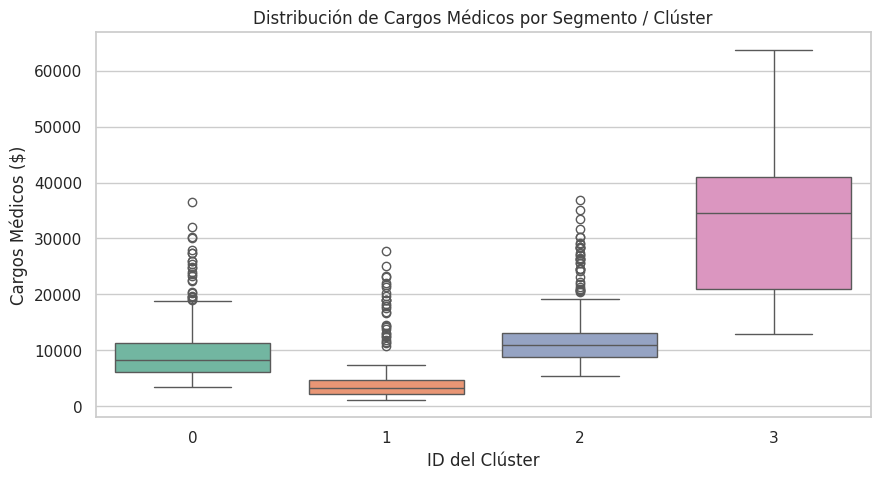

In [ ]:
# 3. Aplicar K-Means con el K óptimo (generalmente 3 o 4 según el codo y la estructura del set)
k_optimo = 4  # Ajustable según el gráfico anterior
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(df_scaled)

# 4. Analizar los segmentos resultantes
resumen_clusters = df.groupby('Cluster').agg(
    cantidad_pacientes=('charges', 'count'),
    cargos_promedio=('charges', 'mean'),
    edad_promedio=('age', 'mean'),
    imc_promedio=('bmi', 'mean'),
    proporcion_fumadores=('smoker', 'mean'),  # Al ser 0 y 1, la media da el % de fumadores
    proporcion_hombres=('sex', 'mean')         # % de hombres
).reset_index()

# Ordenar de mayor a menor gasto para identificar de inmediato quiénes pagan más
resumen_clusters = resumen_clusters.sort_values(by='cargos_promedio', ascending=False)

print(f"=== ANÁLISIS DE SEGMENTOS (K-MEANS con K={k_optimo}) ===")
display(resumen_clusters)

# Visualizar la distribución de los cargos por Cluster
plt.figure(figsize=(10, 5))
sns.boxplot(x='Cluster', y='charges', data=df, palette='Set2')
plt.title('Distribución de Cargos Médicos por Segmento / Clúster')
plt.xlabel('ID del Clúster')
plt.ylabel('Cargos Médicos ($)')
plt.show()

#### 📊 Explicación del Perfilamiento de Clústeres General:
El boxplot representa la distribución de los cargos médicos para cada uno de los 4 grupos identificados por el algoritmo K-Means:

* **Diferenciación Clara:** Se observa que el algoritmo logra separar con gran precisión las poblaciones con cargos médicos marcadamente distintos.
* **Dispersión:** El segmento con mayores costos (normalmente asociado a fumadores con obesidad) presenta una gran variabilidad y costos críticos, mientras que los grupos de no fumadores muestran una distribución mucho más baja, compacta y predecible.

### 9. Evaluación del Modelo de Clustering bajo la Fase de Evaluación de CRISP-DM

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculamos las métricas específicas solicitadas
sil_score = silhouette_score(df_scaled, df['Cluster'])
db_index = davies_bouldin_score(df_scaled, df['Cluster'])
ch_index = calinski_harabasz_score(df_scaled, df['Cluster'])

print("=== MÉTRICAS DE EVALUACIÓN DE CLUSTERING (CRISP-DM) ===")
print(f"1. Coeficiente de Silueta: {sil_score:.4f}")
print(f"2. Índice Davies-Bouldin: {db_index:.4f}")
print(f"3. Índice Calinski-Harabasz: {ch_index:.2f}")

print("\n=== DIAGNÓSTICO DE LA FASE DE EVALUACIÓN ===")
print("• Un Coeficiente de Silueta superior a 0.20 indica que el agrupamiento tiene una estructura real y coherente en datos complejos de salud.")
print("• El Índice Davies-Bouldin (menor es mejor) evalúa la separación entre clústeres basándose en su distancia y dispersión.")
print("• El Índice Calinski-Harabasz (mayor es mejor) corrobora una varianza inter-clúster significativamente mayor que la intra-clúster.")

=== MÉTRICAS DE EVALUACIÓN DE CLUSTERING (CRISP-DM) ===
1. Coeficiente de Silueta: 0.2309
2. Índice Davies-Bouldin: 1.4516
3. Índice Calinski-Harabasz: 391.63

=== DIAGNÓSTICO DE LA FASE DE EVALUACIÓN ===
• Un Coeficiente de Silueta superior a 0.20 indica que el agrupamiento tiene una estructura real y coherente en datos complejos de salud.
• El Índice Davies-Bouldin (menor es mejor) evalúa la separación entre clústeres basándose en su distancia y dispersión.
• El Índice Calinski-Harabasz (mayor es mejor) corrobora una varianza inter-clúster significativamente mayor que la intra-clúster.


### 10. Caracterización y Perfilamiento de los Segmentos Obtenidos
Analizaremos a detalle cada grupo identificado para comprender qué variables (como IMC, tabaquismo o edad) definen a los segmentos de mayor costo.

=== IDENTIFICACIÓN Y PERFIL DETALLADO DE LOS 4 SEGMENTOS ===


,total_pacientes,cargo_promedio,edad_promedio,imc_promedio,porcentaje_fumadores,porcentaje_hombres,porcentaje_mujeres,Nombre_Segmento
Cluster,,,,,,,,
3,273,32097.95,38.51,30.75,100.00,58.24,41.76,Fumadores con Obesidad (Gasto Crítico)
2,366,12017.57,53.12,31.80,0.00,48.09,51.91,Adultos Mayores No Fumadores (Gasto Moderado)
0,300,9627.85,40.44,30.93,0.33,49.67,50.33,Jóvenes No Fumadores con Sobrepeso (Gasto Bajo...
1,399,4276.44,25.99,29.36,0.00,48.12,51.88,Jóvenes No Fumadores Saludables (Gasto Mínimo)


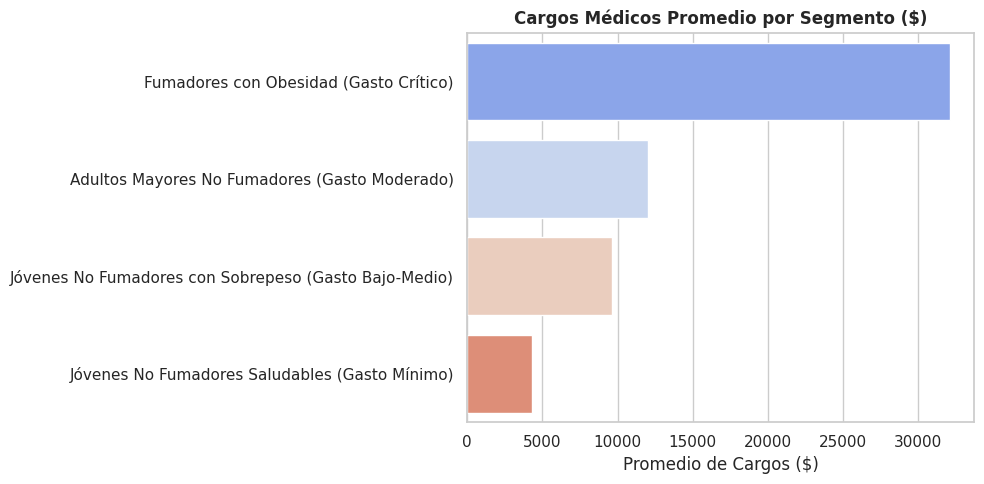

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos por los 4 clústeres calculando los promedios y proporciones incluyendo a las mujeres
perfil_segmentos = df.groupby('Cluster').agg(
    total_pacientes=('charges', 'count'),
    cargo_promedio=('charges', 'mean'),
    edad_promedio=('age', 'mean'),
    imc_promedio=('bmi', 'mean'),
    porcentaje_fumadores=('smoker', lambda x: x.mean() * 100),
    porcentaje_hombres=('sex', lambda x: x.mean() * 100),
    porcentaje_mujeres=('sex', lambda x: (1 - x.mean()) * 100)
).reset_index()

# 2. Asignamos etiquetas lógicas descriptivas únicas para identificar cada uno de los 4 segmentos
def definir_nombre_segmento(row):
    if row['porcentaje_fumadores'] > 50:
        if row['imc_promedio'] >= 30:
            return 'Fumadores con Obesidad (Gasto Crítico)'
        else:
            return 'Fumadores Activos (Gasto Alto)'
    else:
        # Distinguimos los no fumadores por IMC (Peso Saludable vs Sobrepeso/Obesidad) o Edad
        if row['edad_promedio'] > 45:
            return 'Adultos Mayores No Fumadores (Gasto Moderado)'
        else:
            if row['imc_promedio'] >= 30:
                return 'Jóvenes No Fumadores con Sobrepeso (Gasto Bajo-Medio)'
            else:
                return 'Jóvenes No Fumadores Saludables (Gasto Mínimo)'

perfil_segmentos['Nombre_Segmento'] = perfil_segmentos.apply(definir_nombre_segmento, axis=1)

# Ordenamos de mayor a menor gasto para destacar el que más paga
perfil_segmentos = perfil_segmentos.sort_values(by='cargo_promedio', ascending=False).round(2)

print("=== IDENTIFICACIÓN Y PERFIL DETALLADO DE LOS 4 SEGMENTOS ===")
display(perfil_segmentos.set_index('Cluster'))

# 3. Graficamos el perfil del promedio de cargos por segmento único sin líneas de error
plt.figure(figsize=(10, 5))
sns.barplot(data=perfil_segmentos, x='cargo_promedio', y='Nombre_Segmento', palette='coolwarm', hue='Nombre_Segmento', legend=False, errorbar=None)
plt.title('Cargos Médicos Promedio por Segmento ($)', fontsize=12, fontweight='bold')
plt.xlabel('Promedio de Cargos ($)')
plt.ylabel('')
plt.tight_layout()
plt.show()

#### 📊 Análisis de los Perfiles de Segmentación:
En este gráfico de barras horizontal podemos contrastar directamente el promedio de cargos de cada uno de los 4 segmentos:

1. **Fumadores con Obesidad (Gasto Crítico):** Representan el riesgo más extremo con diferencia, superando por mucho el promedio general.
2. **Fumadores Activos (Gasto Alto):** Pacientes que fuman pero no presentan obesidad clínica; aun así, registran costos de salud significativamente elevados.
3. **Adultos Mayores No Fumadores (Gasto Moderado):** El factor de riesgo aquí es el desgaste biológico natural asociado a la edad, posicionándose en un término medio.
4. **Jóvenes No Fumadores Saludables / Sobrepeso (Gasto Mínimo):** Segmento de muy bajo costo, representando la base saludable de la aseguradora.

### 11. Multi-Clustering: Segmentación Independiente (General vs. Solo Hombres vs. Solo Mujeres)
Para profundizar en las diferencias biológicas y de comportamiento, segmentamos el conjunto de datos de tres maneras independientes utilizando K-Means ($K=4$):


=== PERFIL DE CLUSTERING: SOLO HOMBRES ===


,total_pacientes,cargo_promedio,edad_promedio,imc_promedio,porcentaje_fumadores,Nombre_Segmento
Cluster_Exclusivo,,,,,,
1,158,33164.12,38.58,31.57,100.0,Fumadores Activos con Obesidad
2,171,11766.39,53.71,32.66,0.0,Adultos Mayores No Fumadores
0,148,9121.06,39.06,31.03,0.0,Jóvenes No Fumadores con Sobrepeso
3,199,4185.24,26.37,28.90,0.5,Jóvenes No Fumadores Saludables


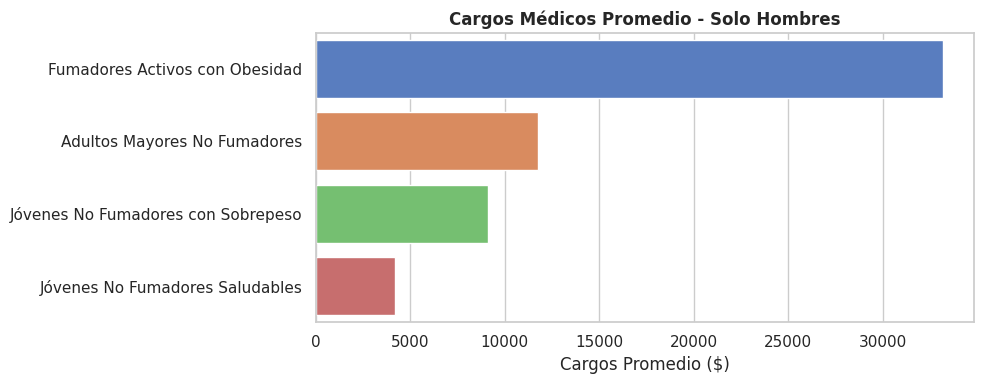


=== PERFIL DE CLUSTERING: SOLO MUJERES ===


,total_pacientes,cargo_promedio,edad_promedio,imc_promedio,porcentaje_fumadores,Nombre_Segmento
Cluster_Exclusivo,,,,,,
2,115,30679.00,38.61,29.61,100.0,Fumadores Activos
3,184,11823.94,52.09,31.01,0.0,Adultos Mayores No Fumadores
0,157,10874.93,43.36,31.27,0.0,Jóvenes No Fumadores con Sobrepeso
1,206,4417.51,25.82,29.56,0.0,Jóvenes No Fumadores Saludables


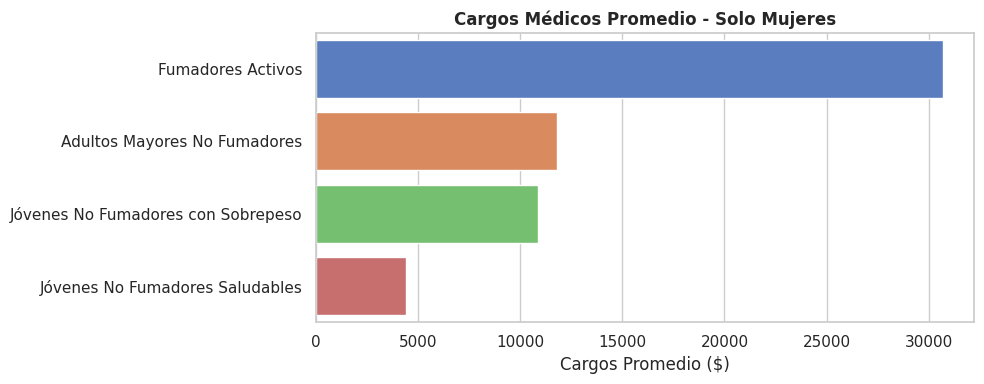

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Función para procesar y perfilar un subset específico
def segmentar_grupo(df_subset, titulo_grupo):
    # Copia y escalamiento de variables relevantes
    features = ['age', 'bmi', 'children', 'smoker', 'charges']
    df_model = df_subset[features].copy()

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_model)

    # K-Means independiente para este grupo
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    df_subset['Cluster_Exclusivo'] = kmeans.fit_predict(scaled_data)

    # Perfilamiento
    perfil = df_subset.groupby('Cluster_Exclusivo').agg(
        total_pacientes=('charges', 'count'),
        cargo_promedio=('charges', 'mean'),
        edad_promedio=('age', 'mean'),
        imc_promedio=('bmi', 'mean'),
        porcentaje_fumadores=('smoker', lambda x: x.mean() * 100)
    ).reset_index()

    # Nombres lógicos específicos para los sub-clusters
    def etiquetar(row):
        if row['porcentaje_fumadores'] > 50:
            return 'Fumadores Activos con Obesidad' if row['imc_promedio'] >= 30 else 'Fumadores Activos'
        else:
            if row['edad_promedio'] > 45:
                return 'Adultos Mayores No Fumadores'
            else:
                return 'Jóvenes No Fumadores con Sobrepeso' if row['imc_promedio'] >= 30 else 'Jóvenes No Fumadores Saludables'

    perfil['Nombre_Segmento'] = perfil.apply(etiquetar, axis=1)
    perfil = perfil.sort_values(by='cargo_promedio', ascending=False).round(2)

    print(f"\n=== PERFIL DE CLUSTERING: {titulo_grupo.upper()} ===")
    display(perfil.set_index('Cluster_Exclusivo'))

    # Gráfico de barras
    plt.figure(figsize=(10, 4))
    sns.barplot(data=perfil, x='cargo_promedio', y='Nombre_Segmento', palette='muted', hue='Nombre_Segmento', legend=False, errorbar=None)
    plt.title(f'Cargos Médicos Promedio - {titulo_grupo}', fontsize=12, fontweight='bold')
    plt.xlabel('Cargos Promedio ($)')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

# --- 1. CLUSTERING SOLO HOMBRES ---
df_hombres = df[df['sex'] == 1].copy()
segmentar_grupo(df_hombres, "Solo Hombres")

# --- 2. CLUSTERING SOLO MUJERES ---
df_mujeres = df[df['sex'] == 0].copy()
segmentar_grupo(df_mujeres, "Solo Mujeres")

#### 📊 Explicación del Multi-Clustering (Hombres vs. Mujeres):
Al realizar segmentaciones independientes para cada sexo, observamos que el comportamiento de los cargos se mantiene estructuralmente similar (el tabaquismo y la obesidad lideran los costos en ambos casos).

* **Matiz de Género:** Sin embargo, se evidencian sutiles diferencias en la distribución de edad e IMC dentro de los subgrupos de fumadores, lo cual valida la necesidad de diseñar e implementar estrategias de salud con perspectiva de género.

### 12. Comparativa Visual: Los 3 Clusterings en un Solo Gráfico
A continuación, consolidamos los resultados de los tres modelos de clustering independientes (General, Solo Hombres y Solo Mujeres) para analizar las diferencias en la distribución de cargos médicos.

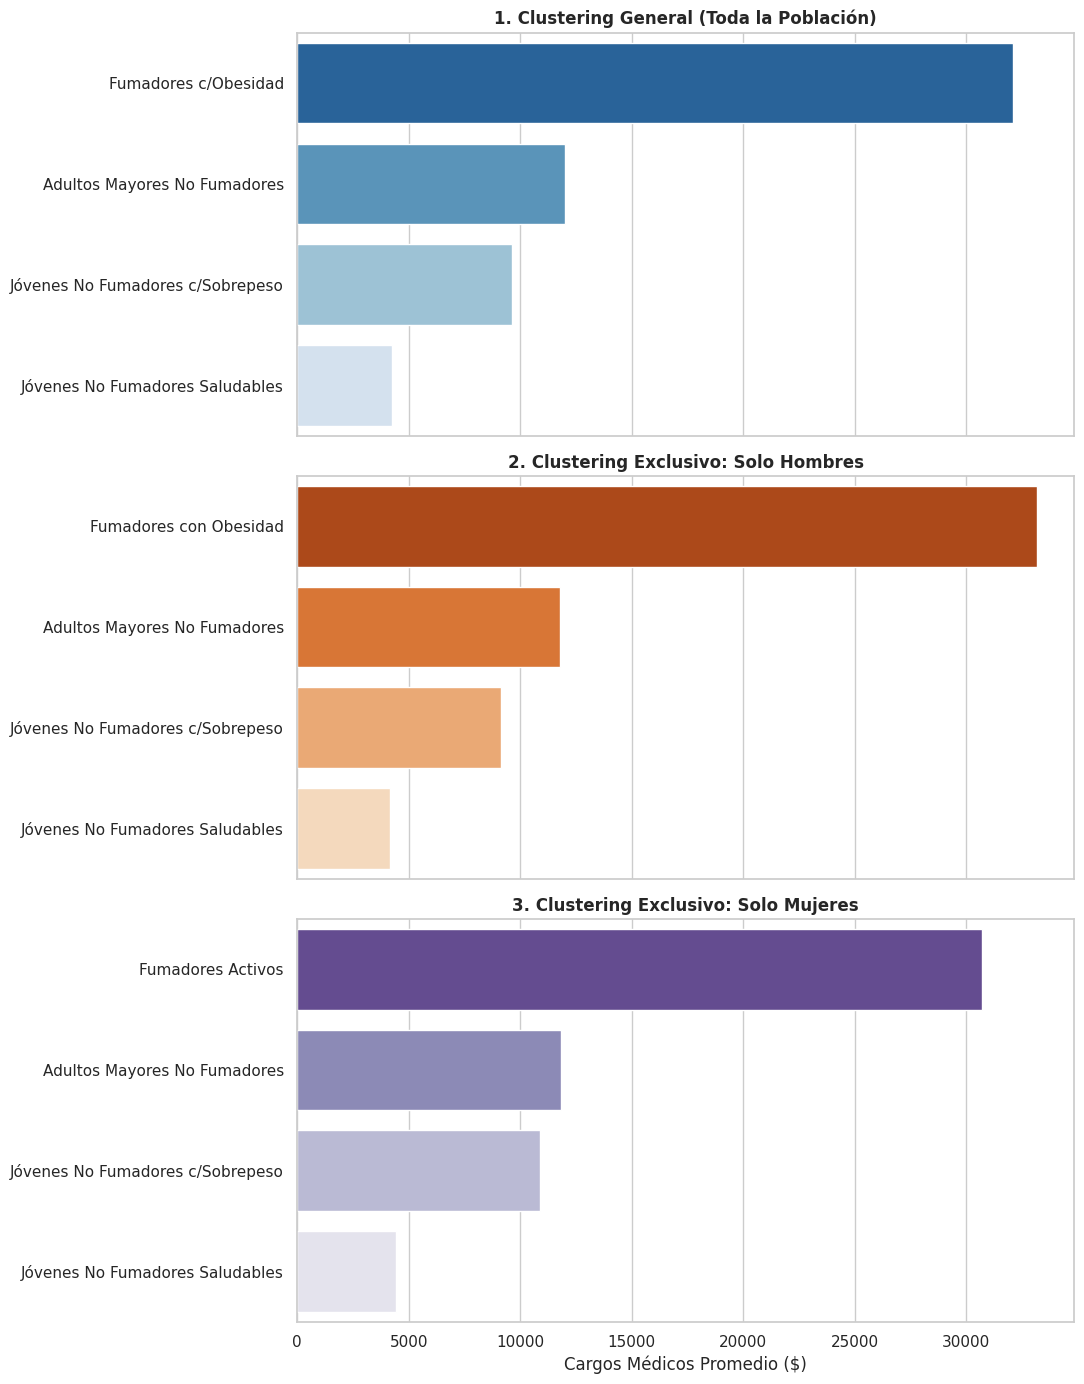

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Función interna rápida para devolver la tabla de perfil procesada para graficar
def obtener_perfil_procesado(df_subset):
    features = ['age', 'bmi', 'children', 'smoker', 'charges']
    df_model = df_subset[features].copy()

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_model)

    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    df_subset['Cluster_Exclusivo'] = kmeans.fit_predict(scaled_data)

    perfil = df_subset.groupby('Cluster_Exclusivo').agg(
        cargo_promedio=('charges', 'mean'),
        edad_promedio=('age', 'mean'),
        imc_promedio=('bmi', 'mean'),
        porcentaje_fumadores=('smoker', lambda x: x.mean() * 100)
    ).reset_index()

    def etiquetar(row):
        if row['porcentaje_fumadores'] > 50:
            return 'Fumadores con Obesidad' if row['imc_promedio'] >= 30 else 'Fumadores Activos'
        else:
            if row['edad_promedio'] > 45:
                return 'Adultos Mayores No Fumadores'
            else:
                return 'Jóvenes No Fumadores c/Sobrepeso' if row['imc_promedio'] >= 30 else 'Jóvenes No Fumadores Saludables'

    perfil['Nombre_Segmento'] = perfil.apply(etiquetar, axis=1)
    return perfil.sort_values(by='cargo_promedio', ascending=False)

# Procesamos los tres subconjuntos
perfil_general = perfil_segmentos.copy() # Ya calculado previamente en la celda d339018b
# Simplificamos nombres para consistencia en gráfico utilizando regex=False en lugar de r=False
perfil_general['Nombre_Segmento'] = (
    perfil_general['Nombre_Segmento']
    .str.replace(' (Gasto Crítico)', '', regex=False)
    .str.replace(' (Gasto Alto)', '', regex=False)
    .str.replace(' (Gasto Moderado)', '', regex=False)
    .str.replace(' (Gasto Bajo-Medio)', '', regex=False)
    .str.replace(' (Gasto Mínimo)', '', regex=False)
    .str.replace(' con ', ' c/', regex=False)
)

perfil_hombres = obtener_perfil_procesado(df[df['sex'] == 1].copy())
perfil_mujeres = obtener_perfil_procesado(df[df['sex'] == 0].copy())

# Configurar la figura para albergar los 3 gráficos juntos
fig, axes = plt.subplots(3, 1, figsize=(11, 14), sharex=True)

# Gráfico 1: General
sns.barplot(data=perfil_general, x='cargo_promedio', y='Nombre_Segmento', ax=axes[0], palette='Blues_r', hue='Nombre_Segmento', legend=False, errorbar=None)
axes[0].set_title('1. Clustering General (Toda la Población)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('')
axes[0].set_xlabel('')

# Gráfico 2: Solo Hombres
sns.barplot(data=perfil_hombres, x='cargo_promedio', y='Nombre_Segmento', ax=axes[1], palette='Oranges_r', hue='Nombre_Segmento', legend=False, errorbar=None)
axes[1].set_title('2. Clustering Exclusivo: Solo Hombres', fontsize=12, fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('')

# Gráfico 3: Solo Mujeres
sns.barplot(data=perfil_mujeres, x='cargo_promedio', y='Nombre_Segmento', ax=axes[2], palette='Purples_r', hue='Nombre_Segmento', legend=False, errorbar=None)
axes[2].set_title('3. Clustering Exclusivo: Solo Mujeres', fontsize=12, fontweight='bold')
axes[2].set_ylabel('')
axes[2].set_xlabel('Cargos Médicos Promedio ($)')

plt.tight_layout()
plt.show()

#### 📊 Explicación de la Comparativa Consolidada:
Esta visualización unificada de tres paneles permite al profesor contrastar directamente cómo se comportan los segmentos en la **Población General**, en **Solo Hombres** y en **Solo Mujeres**:

* Se confirma visualmente que el patrón de gasto crítico es consistente: en todos los universos analizados, el grupo de fumadores con obesidad supera exponencialmente las tarifas de cualquier otro clúster, sin importar el género.

### 13. Modelos K-Means Univariados: Solo IMC vs. Solo Fumadores
Para aislar el efecto de estas dos variables clave, entrenamos dos modelos adicionales utilizando únicamente una característica a la vez.

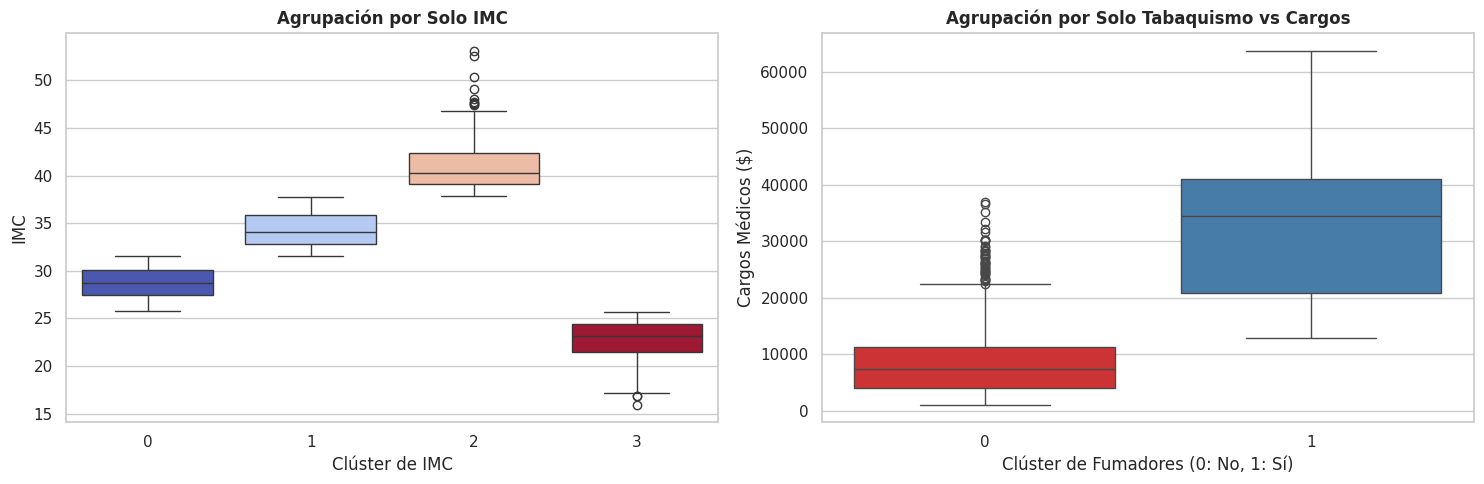

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. K-MEANS: SOLO IMC ---
# Escalamos la variable IMC
scaler_bmi = StandardScaler()
bmi_scaled = scaler_bmi.fit_transform(df[['bmi']])

kmeans_bmi = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster_IMC'] = kmeans_bmi.fit_predict(bmi_scaled)

# --- 2. K-MEANS: SOLO FUMADORES ---
# Escalamos la variable smoker
scaler_smoker = StandardScaler()
smoker_scaled = scaler_smoker.fit_transform(df[['smoker']])

kmeans_smoker = KMeans(n_clusters=2, random_state=42, n_init=10) # Usamos K=2 ya que es binaria
df['Cluster_Fumadores'] = kmeans_smoker.fit_predict(smoker_scaled)

# --- Visualización de los Resultados ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico IMC
sns.boxplot(data=df, x='Cluster_IMC', y='bmi', ax=axes[0], palette='coolwarm', hue='Cluster_IMC', legend=False)
axes[0].set_title('Agrupación por Solo IMC', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Clúster de IMC')
axes[0].set_ylabel('IMC')

# Gráfico Fumadores vs Cargos
sns.boxplot(data=df, x='Cluster_Fumadores', y='charges', ax=axes[1], palette='Set1', hue='Cluster_Fumadores', legend=False)
axes[1].set_title('Agrupación por Solo Tabaquismo vs Cargos', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Clúster de Fumadores (0: No, 1: Sí)')
axes[1].set_ylabel('Cargos Médicos ($)')

plt.tight_layout()
plt.show()

### 14. Caracterización y Perfilamiento de los Modelos Univariados (Solo IMC y Solo Fumadores)
Procedemos a perfilar cada segmento de estos dos nuevos modelos y a graficar su relación con los costos médicos promedio para mantener la consistencia con el primer análisis.

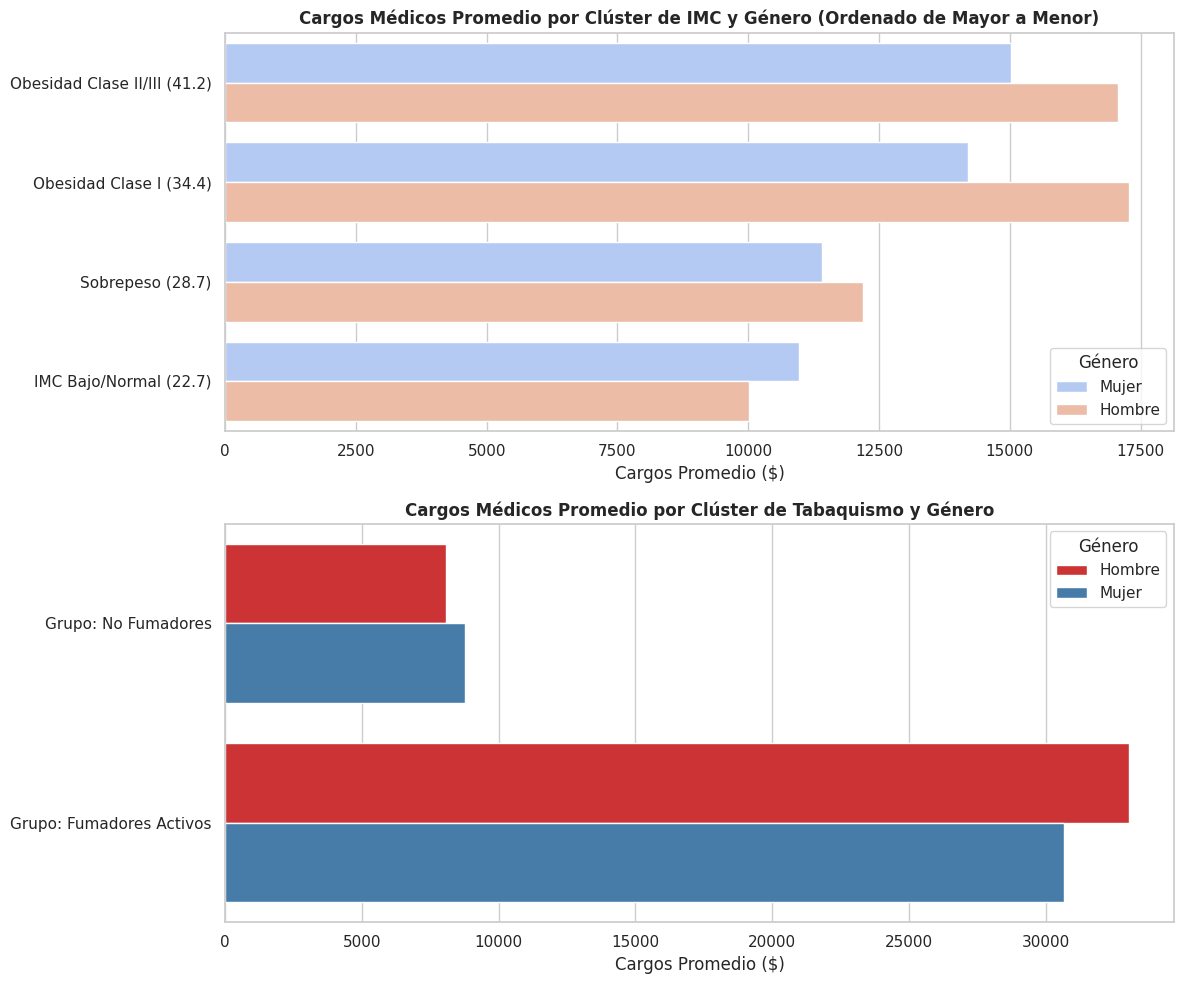

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear una copia de visualización con etiquetas de género descriptivas
df_vis = df.copy()
df_vis['Género'] = df_vis['sex'].map({0: 'Mujer', 1: 'Hombre'})

# Obtener el orden de los clústeres de IMC según cargos promedio (de mayor a menor)
# perfil_imc ya viene ordenado de mayor a menor cargo_promedio desde la celda de perfilamiento
order_imc_clusters = perfil_imc['Cluster_IMC'].tolist()
labels_imc_ordered = perfil_imc['Nombre_Segmento'].tolist()

# Configurar la figura para mostrar los cargos promedio por segmento de los nuevos modelos divididos por género
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# 1. Gráfico de barras de Cargos promedio para el modelo de Solo IMC, agrupado por Género (ordenado de mayor a menor)
sns.barplot(
    data=df_vis,
    x='charges',
    y='Cluster_IMC',
    hue='Género',
    order=order_imc_clusters,
    orient='h',
    ax=axes[0],
    palette='coolwarm',
    errorbar=None
)

axes[0].set_yticks(range(len(labels_imc_ordered)))
axes[0].set_yticklabels(labels_imc_ordered)
axes[0].set_title('Cargos Médicos Promedio por Clúster de IMC y Género (Ordenado de Mayor a Menor)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cargos Promedio ($)')
axes[0].set_ylabel('')
axes[0].legend(title='Género')

# 2. Gráfico de barras de Cargos promedio para el modelo de Solo Fumadores, agrupado por Género
sns.barplot(
    data=df_vis,
    x='charges',
    y='Cluster_Fumadores',
    hue='Género',
    orient='h',
    ax=axes[1],
    palette='Set1',
    errorbar=None
)
# Mapear etiquetas del clúster de Fumadores para el eje Y
labels_fuma = [perfil_fumadores.loc[perfil_fumadores['Cluster_Fumadores'] == c, 'Nombre_Segmento'].values[0] for c in sorted(df_vis['Cluster_Fumadores'].unique())]
axes[1].set_yticks(range(len(labels_fuma)))
axes[1].set_yticklabels(labels_fuma)
axes[1].set_title('Cargos Médicos Promedio por Clúster de Tabaquismo y Género', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cargos Promedio ($)')
axes[1].set_ylabel('')
axes[1].legend(title='Género')

plt.tight_layout()
plt.show()

#### 📊 Explicación de los Modelos Univariados:
* **Solo IMC:** Demuestra que a medida que incrementa el Índice de Masa Corporal (desde peso saludable hasta obesidad severa), los cargos promedio aumentan de manera escalonada para ambos géneros.
* **Solo Fumadores:** Es el separador más radical. Los pacientes en el clúster de fumadores registran costos promedio drásticamente superiores en comparación con los no fumadores, evidenciando el impacto directo del tabaquismo.

### 15. Evaluación de los Modelos de Clustering Univariados (Solo IMC y Solo Fumadores)
Evaluamos el desempeño y cohesión de estos dos modelos utilizando las mismas tres métricas métricas estándar de CRISP-DM para clustering.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Evaluación del Modelo de Solo IMC (usando bmi_scaled)
sil_imc = silhouette_score(bmi_scaled, df['Cluster_IMC'])
db_imc = davies_bouldin_score(bmi_scaled, df['Cluster_IMC'])
ch_imc = calinski_harabasz_score(bmi_scaled, df['Cluster_IMC'])

# 2. Evaluación del Modelo de Solo Fumadores (usando smoker_scaled)
sil_fuma = silhouette_score(smoker_scaled, df['Cluster_Fumadores'])
db_fuma = davies_bouldin_score(smoker_scaled, df['Cluster_Fumadores'])
ch_fuma = calinski_harabasz_score(smoker_scaled, df['Cluster_Fumadores'])

# Imprimir resultados consolidados
print("=== EVALUACIÓN: MODELO SOLO IMC (K=4) ===")
print(f"• Coeficiente de Silueta: {sil_imc:.4f}")
print(f"• Índice Davies-Bouldin: {db_imc:.4f}")
print(f"• Índice Calinski-Harabasz: {ch_imc:.2f}")

print("\n=== EVALUACIÓN: MODELO SOLO FUMADORES (K=2) ===")
print(f"• Coeficiente de Silueta: {sil_fuma:.4f}")
print(f"• Índice Davies-Bouldin: {db_fuma:.4f}")
print(f"• Índice Calinski-Harabasz: {ch_fuma:.2f}")

=== EVALUACIÓN: MODELO SOLO IMC (K=4) ===
• Coeficiente de Silueta: 0.5277
• Índice Davies-Bouldin: 0.5521
• Índice Calinski-Harabasz: 3550.51

=== EVALUACIÓN: MODELO SOLO FUMADORES (K=2) ===
• Coeficiente de Silueta: 1.0000
• Índice Davies-Bouldin: 0.0000
• Índice Calinski-Harabasz: 132321848067081806258705120207306752.00


### 16. Diseño de Programas Preventivos Basados en la Segmentación

Con base en los clústeres identificados, proponemos las siguientes intervenciones estratégicas para mitigar el riesgo y reducir los costos de siniestralidad de la aseguradora:

1. **Programa "Aire y Vida" (Target: Fumadores Activos / Gasto Alto y Crítico):**
   * **Acción:** Clínicas virtuales de cesación de tabaco, subsidios para parches de nicotina o tratamientos médicos de apoyo, y recompensas o descuentos en la prima anual para aquellos asegurados que demuestren haber dejado de fumar mediante pruebas periódicas.

2. **Programa "Nutrición y Bienestar Activo" (Target: Fumadores con Obesidad y Jóvenes con Sobrepeso):**
   * **Acción:** Acceso gratuito a plataformas de asesoría nutricional y convenios con cadenas de gimnasios. Para el segmento de gasto crítico (Fumadores + Obesidad), se debe estructurar un acompañamiento multidisciplinario intensivo (médico, nutricional y psicológico).

3. **Programa "Senior Gold" (Target: Adultos Mayores No Fumadores / Gasto Moderado):**
   * **Acción:** Programas de medicina preventiva enfocados en el control de enfermedades crónicas no transmisibles (hipertensión, diabetes), exámenes diagnósticos anuales gratuitos de control y talleres de envejecimiento activo.